Build and validate end-to-end deployment-ready machine learning pipelines, incorporating automated preprocessing, inference, monitoring, and continuous integration/continuous deployment (CI/CD) workflows.

In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [10]:
def generate_clinical_batch(n_samples=1500, drift_shift=0.0, random_state=42):
    np.random.seed(random_state)
    X_num, y = make_classification(
        n_samples=n_samples, n_features=5, n_informative=4, n_redundant=1, random_state=random_state
    )
    df = pd.DataFrame(X_num, columns=['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose'])
    df['troponin'] = df['troponin'] + drift_shift
    df['glucose'] = df['glucose'] * (1 + drift_shift * 0.5)
    df['admission_type'] = np.random.choice(['Emergency', 'Elective', 'Urgent'], size=n_samples, p=[0.5, 0.3, 0.2])
    df.loc[df.sample(frac=0.04, random_state=random_state).index, 'creatinine'] = np.nan
    df['target'] = y
    return df

In [11]:
num_features = ['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose']
cat_features = ['admission_type']

In [12]:
df_hist = generate_clinical_batch(n_samples=2000, drift_shift=0.0, random_state=42)
X = df_hist[num_features + cat_features]
y = df_hist['target']
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_features)
])

In [13]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [14]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(max_iter=120, learning_rate=0.05, random_state=42))
])

In [15]:
pipeline.fit(X_train, y_train)
print("Model training complete.")

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Model training complete.


In [16]:
import time
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss

In [20]:
def run_ci_validation_gates(pipeline, X_val, y_val, min_auc=0.82, max_latency_ms=25.0):
    probs = pipeline.predict_proba(X_val)[:, 1]
    preds = (probs >= 0.5).astype(int)
    auc = roc_auc_score(y_val, probs)
    f1 = f1_score(y_val, preds)
    brier = brier_score_loss(y_val, probs)
    assert auc >= min_auc, f"CI FAILED: ROC-AUC ({auc:.4f}) < {min_auc}"

    sample_row = X_val.iloc[[0]]
    t0 = time.perf_counter()
    for _ in range(100):
        pipeline.predict_proba(sample_row)
    avg_latency_ms = ((time.perf_counter() - t0) / 100) * 1000
    assert avg_latency_ms <= max_latency_ms, f"CI FAILED: Latency ({avg_latency_ms:.2f}ms) > {max_latency_ms}ms"

    corrupted = sample_row.copy()
    corrupted.iloc[0, 0] = np.nan
    corrupted['admission_type'] = 'UNSEEN_CATEGORY'
    test_prob = pipeline.predict_proba(corrupted)[0, 1]
    assert 0.0 <= test_prob <= 1.0 and not np.isnan(test_prob), "CI FAILED: Null/unseen input error"

    print(f"[CI PASS] AUC: {auc:.4f} | F1: {f1:.4f} | Brier: {brier:.4f} | Latency: {avg_latency_ms:.3f}ms")
    return {"roc_auc": round(auc, 4), "f1": round(f1, 4), "latency_ms": round(avg_latency_ms, 3)}

ci_results = run_ci_validation_gates(pipeline, X_val, y_val)

[CI PASS] AUC: 0.9533 | F1: 0.8821 | Brier: 0.0837 | Latency: 18.207ms


In [21]:
import os
import json
import hashlib
import joblib
from datetime import datetime

In [22]:
deploy_dir = "prod_deployment"
os.makedirs(deploy_dir, exist_ok=True)
prod_model_path = os.path.join(deploy_dir, "active_model.joblib")
baseline_stats_path = os.path.join(deploy_dir, "baseline_stats.json")

In [23]:
joblib.dump(pipeline, prod_model_path, compress=3)

['prod_deployment\\active_model.joblib']

In [24]:
hasher = hashlib.sha256()
with open(prod_model_path, "rb") as f:
    hasher.update(f.read())

In [25]:
ref_quantiles = {}
for col in num_features:
    clean_vals = X_train[col].dropna().values
    bins = np.quantile(clean_vals, np.linspace(0, 1, 11))
    bins[0], bins[-1] = -np.inf, np.inf
    expected_props = np.histogram(clean_vals, bins=bins)[0] / len(clean_vals)
    ref_quantiles[col] = {
        "bins": bins.tolist(),
        "expected_props": np.clip(expected_props, 1e-6, 1.0).tolist()
    }

In [26]:
manifest = {
    "deployed_at": datetime.now().isoformat(),
    "sha256": hasher.hexdigest(),
    "ci_metrics": ci_results,
    "reference_distributions": ref_quantiles
}

In [27]:
with open(baseline_stats_path, "w") as f:
    json.dump(manifest, f, indent=4)

print(f"[CD DEPLOYED] Saved to '{prod_model_path}' (SHA-256: {manifest['sha256'][:12]}...)")

[CD DEPLOYED] Saved to 'prod_deployment\active_model.joblib' (SHA-256: 54d8c809de08...)


In [28]:
import matplotlib.pyplot as plt

In [29]:
def monitor_production_drift(live_df, baseline_path):
    with open(baseline_path, "r") as f:
        ref_dists = json.load(f)["reference_distributions"]
    
    report = []
    for col, stats in ref_dists.items():
        bins = np.array(stats["bins"])
        expected = np.array(stats["expected_props"])
        live_vals = live_df[col].dropna().values
        actual = np.clip(np.histogram(live_vals, bins=bins)[0] / len(live_vals), 1e-6, 1.0)
        psi = np.sum((actual - expected) * np.log(actual / expected))
        status = "CRITICAL DRIFT" if psi >= 0.25 else ("MODERATE SHIFT" if psi >= 0.10 else "STABLE")
        report.append({"Feature": col, "PSI Score": round(float(psi), 4), "Status": status})
    return pd.DataFrame(report)

In [30]:
df_live_stable = generate_clinical_batch(n_samples=1000, drift_shift=0.02, random_state=101)
df_live_drifted = generate_clinical_batch(n_samples=1000, drift_shift=0.85, random_state=202)

In [31]:
drift_w1 = monitor_production_drift(df_live_stable, baseline_stats_path)
drift_w4 = monitor_production_drift(df_live_drifted, baseline_stats_path)
print(drift_w4.to_string(index=False))

    Feature  PSI Score         Status
   age_norm     0.1658 MODERATE SHIFT
   troponin     0.4324 CRITICAL DRIFT
 creatinine     0.1334 MODERATE SHIFT
systolic_bp     0.2783 CRITICAL DRIFT
    glucose     0.3945 CRITICAL DRIFT


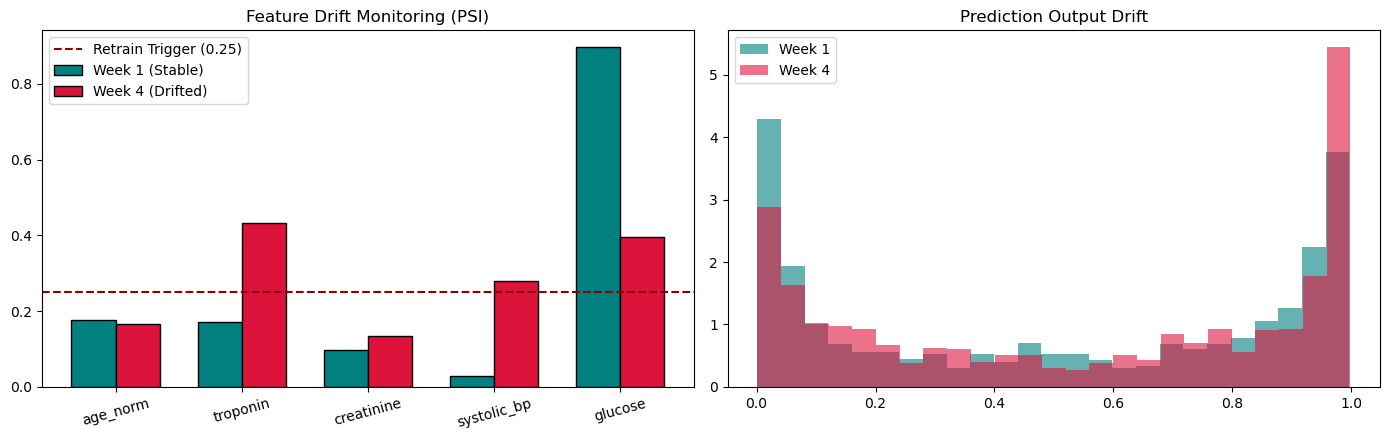

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
x_idx = np.arange(len(num_features))
axes[0].bar(x_idx - 0.175, drift_w1['PSI Score'], 0.35, label='Week 1 (Stable)', color='teal', edgecolor='black')
axes[0].bar(x_idx + 0.175, drift_w4['PSI Score'], 0.35, label='Week 4 (Drifted)', color='crimson', edgecolor='black')
axes[0].axhline(0.25, color='darkred', linestyle='--', label='Retrain Trigger (0.25)')
axes[0].set_xticks(x_idx)
axes[0].set_xticklabels(num_features, rotation=15)
axes[0].set_title("Feature Drift Monitoring (PSI)")
axes[0].legend()

prod_model = joblib.load(prod_model_path)
axes[1].hist(prod_model.predict_proba(df_live_stable[num_features + cat_features])[:, 1], bins=25, alpha=0.6, color='teal', label='Week 1', density=True)
axes[1].hist(prod_model.predict_proba(df_live_drifted[num_features + cat_features])[:, 1], bins=25, alpha=0.6, color='crimson', label='Week 4', density=True)
axes[1].set_title("Prediction Output Drift")
axes[1].legend()

plt.tight_layout()
plt.show()